# Basic Solve

NEST computes MHD equilibria **without assuming nested flux surfaces**. It starts from a DESC
free-boundary equilibrium, keeps that equilibrium's last closed flux surface (LCFS) and flux
coordinates $(\rho, \theta, \zeta)$ as a fixed frame, and then solves for a new current density
$\mathbf{J}$ and pressure $p$ in that frame. Because $\mathbf{J}$ is not tied to flux surfaces, the
solution is free to form magnetic islands. Its magnetic field is

$$
\mathbf{B} = \mathbf{B}_\mathrm{ext} + \mathbf{B}_\mathrm{plasma}[\mathbf{J}],
$$

where $\mathbf{B}_\mathrm{ext}$ is the field of the coils and $\mathbf{B}_\mathrm{plasma}$ is the
free-space Biot–Savart field of $\mathbf{J}$, computed with FFTs on a Cartesian box.

This notebook goes through one solve from start to finish:

1. `DESCInput`: the DESC equilibrium and its coils;
2. `BoundaryPotential`: the current density $\mathbf{J} = \nabla\times\mathbf{T}$, zero on the LCFS;
3. `Pressure`: the pressure;
4. `CartesianGrid`: the periodic box on which $\mathbf{J}$ is sampled for $\mathbf{B}_\mathrm{plasma}$;
5. `ForceResidual`: the force balance $\mathbf{F} = \mathbf{J}\times\mathbf{B} - \nabla p$ of the starting point;
6. `Fields`: $\mathbf{J}$, $\mathbf{B}$, $p$, $\nabla p$ as affine maps of the unknowns;
7. `ObjectiveFunction`: the objective, built from terms;
8. `gauss_newton` and `continuation`: the solve;
9. checking the result on an independent grid;
10. saving and loading the result.

Everything runs at a low resolution so that the notebook takes a few minutes on a laptop CPU.
The last section covers what changes at production resolution.

## Setup

NEST's modules live in `nest/` and are imported by name (as the tests do), so that folder goes on the
path. DESC must be installed (NEST uses DESC's equilibria, bases and optimizer pieces); the
NUFFT library is `nufftax`.

In [1]:
import os
import sys

ROOT = os.path.abspath(os.path.join("..", ".."))  # the NEST repository
sys.path.insert(0, os.path.join(ROOT, "nest"))

If you have access to a GPU, uncomment the following two lines before any DESC or JAX related imports.

In [2]:
# from desc import set_device
# set_device("gpu")

In [3]:
%matplotlib inline
import time

import matplotlib.pyplot as plt
import numpy as np
from desc.grid import QuadratureGrid

from boundary_potential import BoundaryPotential
from cartesian_grid import evaluate_chunked
from desc_input import DESCInput
from fields import Fields
from force import ForceResidual
from grid import CartesianGrid
from objectives import CurrentDistance, FieldDistance, ForceBalance, ObjectiveFunction, PressureDistance
from optimize import continuation
from pressure import Pressure

## 1. The input: a DESC equilibrium and its coils

NEST starts from a **free-boundary** DESC equilibrium: a solution of ideal MHD with nested surfaces
whose LCFS is in balance with a given set of coils. NEST keeps:

- the **LCFS**, which is the fixed boundary of the new solve;
- the **flux coordinates** $(\rho, \theta, \zeta)$. They only serve as a coordinate system for
  $\mathbf{J}$ and $p$; after the solve the field lines need not lie on surfaces $\rho = $ const;
- the **coils**, which give $\mathbf{B}_\mathrm{ext}$.

`desc_input/` holds the prepared equilibria (see its README). Here we use the finite-β
`precise_QA` stellarator (NFP = 2) whose current density goes to zero at the LCFS, in the field of
its 16 helical coils.

In [4]:
EQ = os.path.join(ROOT, "desc_input", "precise_QA_free_boundary_smooth_J",
                  "precise_QA_free_boundary_smooth_J_edgeJ_r0.3.h5")
COILS = os.path.join(ROOT, "desc_input", "precise_QA_free_boundary", "precise_QA_helical_coils.h5")

inp = DESCInput.load(EQ, field=COILS)
inp

DESCInput(precise_QA_free_boundary_smooth_J_edgeJ_r0.3.h5: NFP=2, (L,M,N)=(16, 16, 14), current prescribed, a=0.1728 m, R0=1.048 m, <beta>=0.0104, field=CoilSet)

`DESCInput.load` reads the equilibrium (the last one of an `EquilibriaFamily`) and the external
field, and runs `check()`. The check raises if the input breaks one of NEST's two assumptions:

- DESC's toroidal angle $\zeta$ equals the cylindrical angle $\phi$ (the inverse map from Cartesian
  points to flux coordinates solves only for $\rho$ and $\theta$ at $\zeta = \phi$);
- the Jacobian $\sqrt{g}$ has one sign inside the plasma.

`field` is a file, a DESC field object (e.g. a `CoilSet`), or a list of those, which are summed.
DESC cannot save a sum of fields, so a field made of several parts is kept as one file per part;
see `desc_input/DSHAPE_free_boundary_smooth/` for an example. The summary lists the main properties:

In [5]:
for k, v in inp.summary().items():
    print(f"{k:16s} {v}")

name             precise_QA_free_boundary_smooth_J_edgeJ_r0.3.h5
NFP              2
L, M, N          (16, 16, 14)
sym              True
prescribed       current
a [m]            0.17284789076098897
R0 [m]           1.0475985006835937
V [m^3]          0.6178069332440503
<beta>           0.010445218572322923
external field   CoilSet


| key | meaning |
|---|---|
| `NFP` | number of field periods |
| `L, M, N` | radial, poloidal and toroidal resolution of the DESC equilibrium |
| `sym` | stellarator symmetry of the DESC equilibrium |
| `prescribed` | which profile DESC held fixed: the rotational transform ι or the toroidal current I |
| `a [m]`, `R0 [m]`, `V [m^3]` | minor radius, major radius and volume of the plasma |
| `<beta>` | volume-averaged β |
| `external field` | type of `inp.field`, the source of $\mathbf{B}_\mathrm{ext}$ |

`DESCInput` also gives DESC quantities on a DESC grid (`inp.compute(names, grid)`) or at scattered
flux coordinates (`inp.compute_points(names, rtz)`), and $\mathbf{B}_\mathrm{ext}$ at Cartesian points
(`inp.B_ext(x)`).

## 2. The current density: `BoundaryPotential`

NEST writes $\mathbf{J} = \nabla\times\mathbf{T}$, so $\nabla\cdot\mathbf{J} = 0$ holds for every set of
coefficients. In the radial gauge $T_\rho = 0$, with $f(\rho) = (1-\rho^2)^s$,

$$
\begin{aligned}
T_\theta &= \frac{I}{2\pi}\,h_0(\rho) + \partial_\theta\chi + \rho^2 f(\rho)\, a(\rho,\theta,\zeta), \\
T_\zeta &= \partial_\zeta\chi + f(\rho)\, b(\rho,\theta,\zeta),
\end{aligned}
$$

where

- $a$ and $b$ are Fourier–Zernike series (DESC's `FourierZernikeBasis`);
- $\chi = \sum_{m\neq 0,\,n} \chi_{mn}\, h_{|m|}(\rho)\, F_m(\theta) F_n(\zeta)$, with polynomials
  $h_{|m|}$ chosen so that $h(1) = 1$ and its first $s-1$ derivatives vanish at $\rho = 1$;
- $I$ is the net toroidal current, held fixed.

Every term then makes $\mathbf{J} = O((1-\rho)^{s-1})$ at the LCFS, so **J vanishes on the boundary
for any coefficients**. The construction is also regular on the magnetic axis. The free
coefficients are $u = (\chi_{mn}, a_{lmn}, b_{lmn})$.

`BoundaryPotential.fit` fits $u$ to DESC's own current: it integrates DESC's $\sqrt{g}J^\zeta$ and
$\sqrt{g}J^\theta$ from the axis into a target $\mathbf{T}$ and solves one small least-squares problem
per Fourier mode. Its arguments:

| argument | meaning |
|---|---|
| `L, M, N` | resolution of the basis of $a$, $b$ ($\chi$ uses its $M$, $N$); default `factors` = (3, 3, 2.5) times the equilibrium's |
| `edge_power` | $s$ in $f = (1-\rho^2)^s$, default 2: $\mathbf{J} = O(1-\rho)$ at the LCFS |
| `I` | net toroidal current; default DESC's $I(\rho = 1)$ |
| `sym` | stellarator-symmetric basis (about half the coefficients; for symmetric equilibria) |

We use a small basis, L, M, N = 4, 4, 3:

In [6]:
L, M, N = 4, 4, 3
current = BoundaryPotential.fit(inp.eq, L, M, N)
print(f"free coefficients: {current.n_free} ({len(current.chi_modes)} chi, "
      f"{current.basis.num_modes} a, {current.basis.num_modes} b); I = {current.I:.1f} A; "
      f"edge power s = {current.edge_power}")

free coefficients: 266 (56 chi, 105 a, 105 b); I = 5548.6 A; edge power s = 2


`current.point_evaluator()` gives a jitted function of $(\rho, \theta, \zeta)$ that returns $\mathbf{J}$ in
$(R, \phi, Z)$ components; `evaluate_chunked` calls it on many points. Here we compare the fit
with DESC's $\mathbf{J}$ on the cross-section $\zeta = 0$:

rms |J_fit - J_DESC| / rms |J_DESC| = 0.020


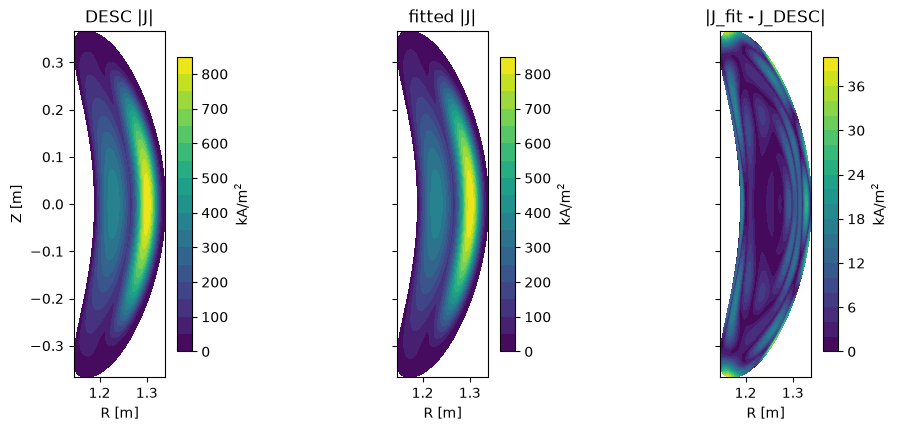

In [7]:
rho, theta = np.meshgrid(np.linspace(0.02, 1, 40), np.linspace(0, 2 * np.pi, 121))
rtz = np.column_stack([rho.ravel(), theta.ravel(), np.zeros(rho.size)])
xyz = inp.basis_vectors(rtz)["x"]  # Cartesian positions; at phi = 0, x = R and z = Z
R, Z = xyz[:, 0].reshape(rho.shape), xyz[:, 2].reshape(rho.shape)

J_desc = inp.compute_points(["J"], rtz)["J"]
J_fit = evaluate_chunked(current.point_evaluator(), rtz)
absJ = lambda J: np.linalg.norm(J, axis=1).reshape(rho.shape) / 1e3  # kA/m^2


def plot_sections(panels):  # filled contours of (data, title, levels), one panel each
    fig, ax = plt.subplots(1, len(panels), figsize=(3.2 * len(panels), 4.2), sharey=True,
                           constrained_layout=True)
    for a, (data, title, levels) in zip(ax, panels):
        c = a.contourf(R, Z, data, levels)
        fig.colorbar(c, ax=a, label="kA/m$^2$", shrink=0.85)
        a.set_title(title)
        a.set_xlabel("R [m]")
        a.set_aspect("equal")
    ax[0].set_ylabel("Z [m]")


levels = np.linspace(0, 50 * np.ceil(absJ(J_desc).max() / 50), 18)  # kA/m^2, shared by the |J| panels
plot_sections([(absJ(J_desc), "DESC |J|", levels), (absJ(J_fit), "fitted |J|", levels),
               (absJ(J_fit - J_desc), "|J_fit - J_DESC|", 20)])
err = np.sqrt(np.mean(absJ(J_fit - J_desc) ** 2) / np.mean(absJ(J_desc) ** 2))
print(f"rms |J_fit - J_DESC| / rms |J_DESC| = {err:.3f}")

At this small basis the fit is within a few percent of DESC's current; a larger basis (the default is
3× the equilibrium's resolution in $L$ and $M$) fits more closely. The fit is only the starting point:
the solve below changes $u$.

## 3. The pressure: `Pressure`

The pressure is its own Fourier–Zernike series in the same flux coordinates, so it can vary on a
surface $\rho = $ const once $\mathbf{J}$ does. With `edge_order` $k$,
$p = (1-\rho^2)^{k+1}\, Q(\rho, \theta, \zeta)$, so that $p$ and its first $k$ radial derivatives vanish at
the LCFS. Without it, $p = 0$ on the LCFS is imposed as a linear constraint on the coefficients.
`Pressure.fit` fits DESC's $p(\rho)$:

In [8]:
pressure = Pressure.fit(inp.eq, L, M, N, edge_order=2)
free, _ = pressure.free_coefficients()
print(f"{pressure.basis.num_modes} coefficients, {len(free)} free; edge order {pressure.edge_order}")

105 coefficients, 105 free; edge order 2


## 4. The box: `CartesianGrid`

$\mathbf{B}_\mathrm{plasma}$ is computed spectrally. $\mathbf{J}$ is sampled on a periodic Cartesian box,
Fourier transformed, and multiplied by the free-space Green's function; the result is evaluated at
any points with a non-uniform FFT. `CartesianGrid.periodic_box(inp, h, factor=2)` builds a box with
spacing $h$ whose period is at least `factor` times the plasma's extent in each direction (2× is
what the free-space kernels need to remove the periodic images). `locate_plasma` finds the box
points inside the plasma and their flux coordinates by a Newton inverse map; it is done once per box.

The box spacing sets the resolution of $\mathbf{B}_\mathrm{plasma}$; it is given as $h = a/\mathrm{frac}$.
Here frac = 4, which is coarse:

In [9]:
frac = 4
box = CartesianGrid.periodic_box(inp, inp.a / frac).locate_plasma(inp)
print(f"box {box.shape}, h = {box.dx[0] * 100:.2f} cm, {len(box.inside):,} points inside the plasma")

box (125, 125, 40), h = 4.32 cm, 7,642 points inside the plasma


## 5. The starting point: `ForceResidual`

`ForceResidual` evaluates the force balance on its own collocation points: a DESC
`QuadratureGrid` over one field period (Gauss–Legendre in $\rho$, uniform in $\theta$ and $\zeta$), with
volume weights $|\sqrt{g}|\,w$. The box is used only to sample $\mathbf{J}$ for the FFT.

| argument | meaning |
|---|---|
| `grid` | collocation points; default `QuadratureGrid(2L, 2M, 2N)` of the equilibrium |
| `kernel` | `"vico_greengard"` (default; the Vico–Greengard truncated kernel, spectrally accurate) or `"hockney"` (the discrete Biot–Savart sum, second order in $h$) |
| `dtype` | precision of the FFTs and the NUFFT (float32 by default, enough for diagnostics; the solve uses float64) |
| `bs_kw` | other `BiotSavart` arguments: NUFFT `eps`, `upsampfac`, kernel `R_cut`, `cache_dir`, ... |
| `sym` | use only the half $\theta \in [0, \pi]$ of a stellarator-symmetric grid |

We evaluate the fitted $\mathbf{J}$ and $p$ on an evaluation grid three times finer than the solve
basis. The force error is reported as DESC does,
$\langle|\mathbf{F}|\rangle_\mathrm{vol} / \langle|\nabla B^2/2\mu_0|\rangle_\mathrm{vol}$, overall and in radial bins:

In [10]:
geval = QuadratureGrid(L=3 * L, M=3 * M, N=3 * N, NFP=inp.NFP)
ev = ForceResidual(inp, box, geval, dtype=np.float64)
out0 = ev.evaluate(current, pressure)
bins = (0.0, 0.5, 0.8, 1.0)
m0 = ev.metrics(out0["F"], rho_bins=bins)
print(f"{len(ev.x):,} evaluation points; force error {m0['mean']:.3e} "
      f"(DESC's own on this grid: {ev.F_desc_vol / ev.norm:.3e})")
print("by radius:", {k: f"{v:.2e}" for k, v in m0["bins"].items()})

3,325 evaluation points; force error 1.121e-03 (DESC's own on this grid: 4.236e-05)
by radius: {'0-0.5': '1.23e-03', '0.5-0.8': '1.25e-03', '0.8-1': '8.65e-04'}


`decompose` splits $\mathbf{F}$ exactly against DESC's fields at the same points into four parts:
DESC's own imbalance, the error of the fitted current, the error of the field
($\mathbf{B}_\mathrm{ext} + \mathbf{B}_\mathrm{plasma}$ against DESC's $\mathbf{B}$), and the error of the
pressure. The pressure part is at round-off: DESC's $p \propto (1-\rho^2)^3$ is represented exactly
with `edge_order=2`.

In [11]:
parts, residual, _ = ev.decompose(out0)
for name, Fp in parts.items():
    print(f"{name:40s} {ev.metrics(Fp)['mean']:.2e}")
print(f"{'identity residual (max |F - sum|)':40s} {np.abs(residual).max():.1e}")

DESC force balance                       4.14e-05
current fit (J - J_desc) x B_desc        9.76e-04
field (B - B_desc), x J                  4.39e-04
pressure fit -(grad p - grad p_desc)     1.12e-16
identity residual (max |F - sum|)        8.0e-11


## 6. The unknowns and the affine maps: `Fields`

The state is $x = (u, x_p)$: the current coefficients and the free pressure coefficients. At fixed
collocation points every field is affine in $x$:

$$
\mathbf{J} = \mathbf{J}_0 + D_J u, \qquad \mathbf{B} = \mathbf{B}_0 + D_B u, \qquad p = D_p x_p, \qquad \nabla p = D_{\nabla p} x_p,
$$

with $\mathbf{J}_0$ the net-current term and $\mathbf{B}_0 = \mathbf{B}_\mathrm{ext} + \mathrm{BS}_h(\mathbf{J}_0)$.
The matrices are constant, so once they are built the objective needs no further Biot–Savart call.
$D_B$ is the expensive one: one Biot–Savart application per current coefficient.

`Fields` is a `ForceResidual` (same points, weights, $\mathbf{B}_\mathrm{ext}$ and normalization) plus
these matrices:

| argument | meaning |
|---|---|
| `grid` | collocation points; default `QuadratureGrid(2L, 2M, 2N)` of the **current basis** (2× rule) |
| `kernel`, `bs_kw` | as for `ForceResidual`; always float64 |
| `col_chunk` | $D_B$ columns per batched Biot–Savart call (memory) |
| `cache_dir` | save $D_B$ in column blocks and resume an interrupted build (opt-in) |
| `build_D_B` | `False` for an evaluation-only object |

With stellarator-symmetric bases (`fit(..., sym=True)` for both current and pressure) `Fields`
uses the half grid automatically.

In [12]:
t0 = time.time()
F = Fields(inp, current, pressure, box, col_chunk=8)
print(f"built in {time.time() - t0:.0f} s: {len(F.x):,} points, {F.n_u} + {F.n_p} = {F.n} unknowns; "
      f"D_B {F.D_B.shape}, {F.D_B.nbytes / 1e6:.1f} MB")

Fields: collocation: 1,105 points, 266 current + 105 pressure coefficients; box (125, 125, 40), 7,642 inside points, kernel vico_greengard
Fields: D_J, D_p, D_gp built (2.5 s): 0.01 GB
Fields: box geometry at 7,642 points (0.5 s)
  D_B chunk 1/34: 8/266 columns, 0.30 s/column, memory {'host_peak_GB': 1.595}, 2s elapsed, ETA 77s
  D_B chunk 31/34: 248/266 columns, 0.13 s/column, memory {'host_peak_GB': 1.595}, 33s elapsed, ETA 2s
  D_B chunk 34/34: 266/266 columns, 0.14 s/column, memory {'host_peak_GB': 1.595}, 36s elapsed, ETA 0s
built in 44 s: 1,105 points, 266 + 105 = 371 unknowns; D_B (1105, 3, 266), 7.1 MB


`F.initial_state()` is the fitted state. `F.fit_pressure(x)` replaces its pressure by the
**force-optimal** one: the least-squares solution of $\nabla p = \mathbf{J}\times\mathbf{B}$ for the
current of $x$. That is a better start than DESC's $p(\rho)$:

In [13]:
x_fit = F.initial_state()
x0 = F.fit_pressure(x_fit)
print(f"force error at the fitted state: {F.report(x_fit)['mean']:.3e}; "
      f"with the force-optimal pressure: {F.report(x0)['mean']:.3e}")

force error at the fitted state: 1.077e-03; with the force-optimal pressure: 9.956e-04


## 7. The objective: terms

An objective is a weighted sum of residual terms, $f(x) = \sum_i w_i \|r_i(x)\|^2$. Every term
carries the volume weights, so $\|r_i\|^2$ is a volume average:

| term | residual |
|---|---|
| `ForceBalance` | $(\mathbf{J}\times\mathbf{B} - \nabla p)/F_0$, $F_0 = \langle|\nabla B^2/2\mu_0|\rangle_\mathrm{vol}$ of DESC |
| `FieldDistance` | $(\mathbf{B} - \mathbf{B}_\mathrm{target})/\mathrm{rms}\,|\mathbf{B}_\mathrm{target}|$, target default DESC's $\mathbf{B}$ |
| `CurrentDistance` | $(\mathbf{J} - \mathbf{J}_\mathrm{target})/\mathrm{rms}\,|\mathbf{J}_\mathrm{target}|$ |
| `PressureDistance` | $(p - p_\mathrm{target})/\mathrm{rms}\,p_\mathrm{target}$ |

Force balance alone is ill-posed: it does not fix the profiles, and its minima depend on the
resolution and on the path taken. NEST therefore minimizes the **field distance plus force balance**,

$$
f(x) = \|r_D(x)\|^2 + \lambda^{-1}\,\|r_F(x)\|^2,
$$

and lowers $\lambda$ step by step (continuation). The solution then moves away from DESC's field
only as far as force balance requires. A term with weight 0 is only reported. New terms subclass
`objectives.Term`.

In [14]:
obj = ObjectiveFunction(F, [FieldDistance(F), ForceBalance(F), PressureDistance(F, weight=0),
                            CurrentDistance(F, weight=0)])
s0 = obj.summary(x0)
print({k: f"{v:.3e}" for k, v in s0.items()})

{'field': '2.115e-03', 'force': '1.322e-03', 'pressure': '2.188e-03', 'current': '2.508e-02', 'f': '6.222e-06', '<|F|>/F_0': '9.956e-04'}


`summary` gives the unweighted norm of every term, the weighted total `f`, and DESC's force measure
`<|F|>/F_0`. The Jacobian is assembled from the constant matrices, structured by term
(`obj.jacobian(x)`, or in blocks of points with `obj.blocks`).

## 8. The solve

`gauss_newton` is a Gauss–Newton trust-region method built from DESC's own least-squares pieces:
column scaling, the exact trust-region subproblem, and the radius update. Its main arguments:

| argument | meaning |
|---|---|
| `maxiter` | maximum number of iterations |
| `tr_method` | `"cho"` (from $J^TJ$, default; refused if it would square a large condition number), `"qr"`, or `"auto"` |
| `points_per_block` | row chunking: the Jacobian is never formed; only $J^TJ$ or a QR factor is accumulated over blocks of points |
| `ftol` | also stop when the relative reduction of $f$ falls below it |
| `log_path`, `checkpoint` | a JSON line per step, and $x$ saved after every step |

It stops with `"reduction_at_rounding"` when the predicted reduction is at the level of the rounding
error of $f$, where no more progress is possible. With `verbose=True` every trial step prints one
JSON line.

`continuation` runs `gauss_newton` for a list of term weights, each warm-started from the last.
We set $\lambda_\mathrm{ref}$ so that the force term equals a field distance of $10^{-3}$ at the start,
and use $\lambda = 10^{2}, 1, 10^{-2}$ times $\lambda_\mathrm{ref}$:

In [15]:
lam_ref = s0["force"] ** 2 / 1e-3**2
lams = lam_ref * 10.0 ** np.array([2, 0, -2])
results = continuation(obj, x0, [(1, 1 / lam, 0, 0) for lam in lams], maxiter=50, verbose=False)
for lam, r in zip(lams, results):
    s = r["summary"]
    print(f"lambda/lambda_ref = {lam / lam_ref:g}: {len(r['history'])} trial steps, {r['stop_reason']}; "
          f"field {s['field']:.3e}, force {s['force']:.3e}, <|F|>/F_0 {s['<|F|>/F_0']:.3e}")

lambda/lambda_ref = 100: 4 trial steps, reduction_at_rounding; field 1.473e-03, force 3.809e-03, <|F|>/F_0 2.755e-03
lambda/lambda_ref = 1: 5 trial steps, reduction_at_rounding; field 1.671e-03, force 1.085e-03, <|F|>/F_0 8.725e-04
lambda/lambda_ref = 0.01: 8 trial steps, reduction_at_rounding; field 2.891e-03, force 6.786e-04, <|F|>/F_0 4.943e-04


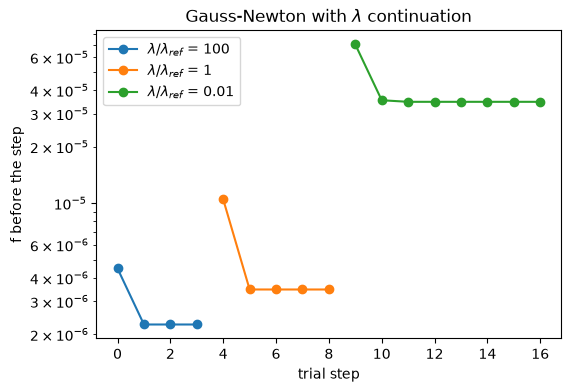

In [16]:
fig, ax = plt.subplots(figsize=(6, 4))
k0 = 0
for lam, r in zip(lams, results):
    f = [h["f"] for h in r["history"]]
    ax.semilogy(range(k0, k0 + len(f)), f, "o-", label=rf"$\lambda/\lambda_{{ref}}$ = {lam / lam_ref:g}")
    k0 += len(f)
ax.set_xlabel("trial step")
ax.set_ylabel("f before the step")
ax.set_title(r"Gauss-Newton with $\lambda$ continuation")
ax.legend();

As $\lambda$ decreases, the force term falls and the field moves further from DESC's. Each solve stops
at the rounding level. The objective $f$ jumps between stages because its weights change.

The pressure is solved for together with the current. `F.objects(x)` turns a state back into a
`BoundaryPotential` and a `Pressure`, which every other part of NEST accepts.

## 9. Checking the result on an independent grid

The solve only sees its collocation points. A force that is small there but large in between would
signal an under-resolved problem, so we evaluate the end state on the finer grid of section 5.
`ForceResidual.evaluate` evaluates the series at its points and computes $\mathbf{B}_\mathrm{plasma}$ by
one Biot–Savart application; no matrices are involved:

In [17]:
x = results[-1]["x"]
current_x, pressure_x = F.objects(x)
out = ev.evaluate(current_x, pressure_x)
m = ev.metrics(out["F"], rho_bins=bins)
print(f"force error on the evaluation grid: start {m0['mean']:.3e} -> end {m['mean']:.3e} "
      f"(on the solve grid: {results[-1]['summary']['<|F|>/F_0']:.3e})")
print("by radius:", {k: f"{v:.2e}" for k, v in m["bins"].items()})

force error on the evaluation grid: start 1.121e-03 -> end 5.195e-04 (on the solve grid: 4.943e-04)
by radius: {'0-0.5': '6.48e-04', '0.5-0.8': '6.61e-04', '0.8-1': '2.38e-04'}


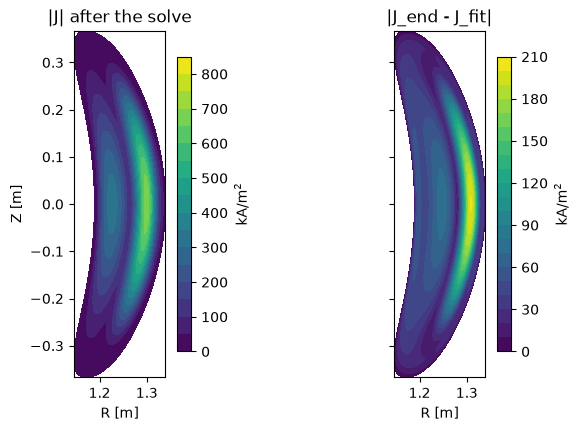

In [18]:
J_end = evaluate_chunked(current_x.point_evaluator(), rtz)
plot_sections([(absJ(J_end), "|J| after the solve", levels),
               (absJ(J_end - J_fit), "|J_end - J_fit|", 20)])

At the last λ the current has moved by up to about a quarter of its peak, while the field has moved by only 0.3 % rms (field distance 2.9e-3): many currents give nearly the same field, and force balance picks among them. These numbers belong to this coarse problem (a 4, 4, 3 basis, h = a/4); converged statements need the resolution checks of the last section.

## 10. Saving and loading

The series save to `.npz` files and load against the same equilibrium:

In [19]:
current_x.save("tutorial_current.npz")
pressure_x.save("tutorial_pressure.npz")
c2 = BoundaryPotential.load("tutorial_current.npz", inp.eq)
p2 = Pressure.load("tutorial_pressure.npz", inp.eq)
print(np.array_equal(c2.u, current_x.u), np.array_equal(p2.c, pressure_x.c))
os.remove("tutorial_current.npz")
os.remove("tutorial_pressure.npz")

True True


## Stellarator symmetry

`precise_QA` is stellarator symmetric. Fitting both series with `sym=True` keeps only the symmetric
modes, and `Fields` then uses only the half $\theta \in [0, \pi]$ of its grid: about half the points
and half the unknowns. The result equals that of the full solve when the external field is symmetric.
These coils are symmetric only to about $10^{-4}$ of $|\mathbf{B}|$, so a symmetric solve here solves
the symmetrized problem.

In [20]:
current_s = BoundaryPotential.fit(inp.eq, L, M, N, sym=True)
pressure_s = Pressure.fit(inp.eq, L, M, N, edge_order=2, sym=True)
print(f"current coefficients: {current.n_free} -> {current_s.n_free}; "
      f"pressure: {pressure.basis.num_modes} -> {pressure_s.basis.num_modes}")

current coefficients: 266 -> 136; pressure: 105 -> 54


## Production runs

The same steps run at the equilibrium's resolution with `nest/run_solve.py`. It does sections 1–9,
with λ continuation, and writes `run_solve.json` and the states `x_<k>.npy`:

```bash
sbatch run.sbatch nest/run_solve.py --frac 10 --cache-dir $SCRATCH/nest_cache
```

What changes at scale:

- **Memory.** $D_B$ has (points × 3 × current coefficients) entries in float64. At the equilibrium
  resolution of this case that is of order 15 GB, about half with `sym=True`. `--col-chunk` sets the
  batch of Biot–Savart calls and `--points-per-block` the row chunking of the Gauss–Newton step;
  every progress line reports the device memory.
- **Time.** $D_B$ costs one Biot–Savart application per coefficient. With `--cache-dir` the columns are
  saved in blocks, so a job that stops resumes where it left off.
- **Resolution.** Use the default 2× collocation grid and check every end state on an independent,
  finer grid (`--eval-factor`). The box spacing `--frac` sets the accuracy of $\mathbf{B}_\mathrm{plasma}$.

`TODO.md` lists open work; `UPDATES.md` records every change with its checks.